# Can Your AI Admit It Doesn't Know? — Open-Set Leaf Classification
This notebook **loads saved results** (`data/metadata.csv`, `artifacts/predictions/*.npz`, `artifacts/metrics/*.json`) and re-derives every headline number with the audited functions in `src/open_set.py`; it never retrains. Each recomputed value is asserted equal to the saved one.

## 1. Research question and hypotheses
**RQ:** When a leaf belongs to a species never seen in training, can a classifier recognise that it may not know the answer, using only its own confidence?

Expectations (from `PROJECT_PLAN.md`; they are hypotheses to be checked, not facts):
- **H1** Both models classify the five known species with high closed-set accuracy.
- **H2** The pretrained MobileNetV3-Small separates known from unknown better than HOG + SVM.
- **H3** Even the better model will accept some unknown leaves, especially a species resembling a known one (Potato vs Tomato).
- **H4** Rejecting more predictions lowers error among accepted ones at the cost of coverage.

In [1]:
import json, os, sys
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "configs").exists(): ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import confusion_matrix, roc_curve
from src.open_set import (select_threshold, max_confidence, known_metrics, unknown_metrics, auroc_unknown_vs_known,
                          combined_correctness, combined_risk_at_threshold, risk_coverage)
cfg = json.load(open("configs/experiment.json")); classes = list(cfg["known"])
df = pd.read_csv("data/metadata.csv")
R = json.load(open("artifacts/metrics/open_set_results.json"))
P = {k: np.load(f"artifacts/predictions/{k}.npz") for k in ("hog_svm", "mobilenet")}
NAMES = {"hog_svm": "HOG + SVM", "mobilenet": "MobileNetV3-Small"}; COL = {"hog_svm": "#c0762b", "mobilenet": "#2b6cc0"}
te, va, unk = df[df.split == "test"], df[df.split == "val"], df[df.split == "unknown_test"]
y = te.label.values
print("ROOT:", ROOT, "| known test n =", len(te), "| val n =", len(va), "| unknown n =", len(unk))

ROOT: /Users/aayushtomar/DS_leaf | known test n = 188 | val n = 187 | unknown n = 300


## 2. Dataset composition, class mapping and split design

In [2]:
print("class -> label:", {c: i for i, c in enumerate(classes)})
print("source folders:", {**cfg["known"], **cfg["unknown"]})
df.groupby(["species", "split"]).size().unstack(fill_value=0)

class -> label: {'Apple': 0, 'Corn': 1, 'Grape': 2, 'Peach': 3, 'Tomato': 4}
source folders: {'Apple': 'Apple___healthy', 'Corn': 'Corn_(maize)___healthy', 'Grape': 'Grape___healthy', 'Peach': 'Peach___healthy', 'Tomato': 'Tomato___healthy', 'Potato': 'Potato___healthy', 'Bell pepper': 'Pepper,_bell___healthy'}


split,test,train,unknown_test,val
species,,,,
Apple,38,175,0,37
Bell pepper,0,0,150,0
Corn,37,175,0,38
Grape,38,175,0,37
Peach,38,175,0,37
Potato,0,0,150,0
Tomato,37,175,0,38


**Design.** Only *healthy* PlantVillage `raw/color` leaves (target = species, not disease). 250 images per known species, split 70/15/15 **stratified at image level** after exact-duplicate (SHA-256) removal. Potato and Bell pepper (150 each) are **never** used in training or validation; they form a test-only unknown pool.

**Caveat (important).** PlantVillage has no physical-leaf IDs, so several photographs of one leaf may sit in different splits. Section 12 quantifies and stress-tests this.

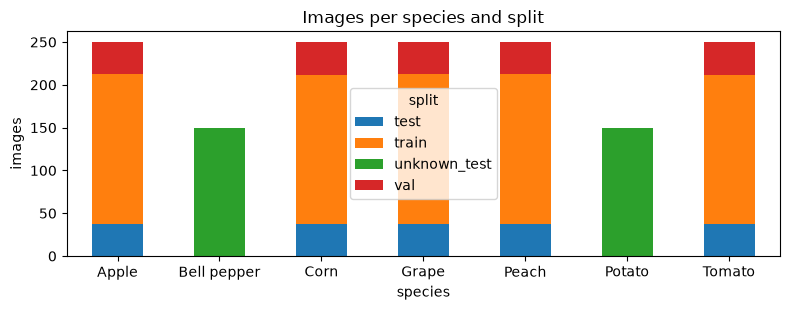

In [3]:
assert set(df[df.split == "train"].role) == {"known"} and set(unk.species) == {"Potato", "Bell pepper"}
fig, ax = plt.subplots(figsize=(8, 3.2)); t = df.groupby(["species", "split"]).size().unstack(fill_value=0)
t.plot.bar(stacked=True, ax=ax, rot=0); ax.set_ylabel("images"); ax.set_title("Images per species and split"); plt.tight_layout(); plt.show()

## 3. Sample montage

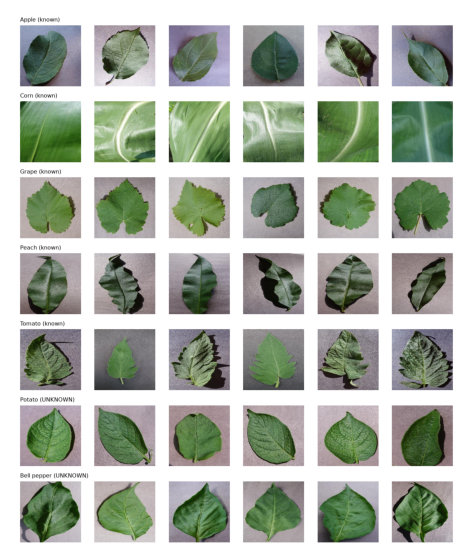

In [4]:
plt.figure(figsize=(11, 7)); plt.imshow(Image.open("artifacts/figures/sample_montage.png")); plt.axis("off"); plt.show()

## 4. Methodology
- **HOG + SVM:** grayscale → 128×128 → HOG (9 orientations, 16×16 cells, 2×2 blocks, 1764 features) → RBF-SVM (C=10, Platt-scaled probabilities).
- **MobileNetV3-Small:** ImageNet weights, backbone frozen, new 5-way head, light augmentation, best epoch by validation loss.
- **Confidence** = maximum class probability. **Rejection:** output *Unknown / Uncertain* when confidence < threshold. Both models use identical splits and the same rule.

## 5. Known-class performance and confusion matrices

,model,n,accuracy,macro_f1,coverage,false_rejection_rate,accuracy_on_accepted
0,HOG + SVM,188,0.989,0.99,0.984,0.016,0.989
1,MobileNetV3-Small,188,1.000,1.00,0.947,0.053,1.000


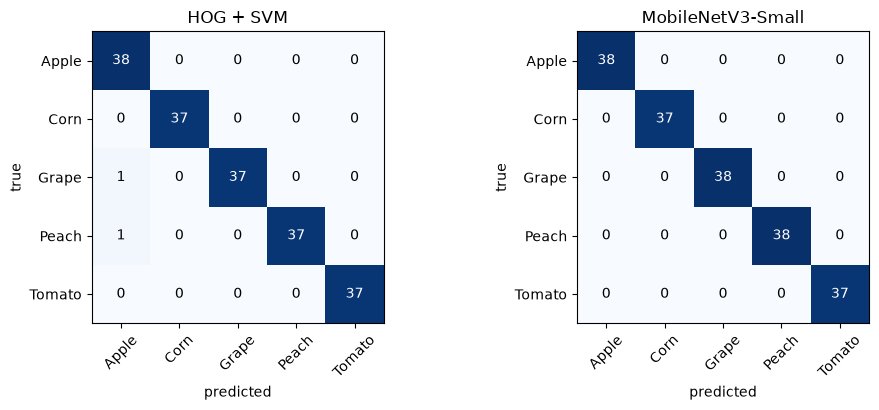

In [5]:
rows = []
for k in P:
    m = known_metrics(P[k]["test_probs"], y, R[k]["threshold"])
    assert abs(m["accuracy"] - R[k]["known_test"]["accuracy"]) < 1e-12
    rows.append({"model": NAMES[k], **{a: round(b, 3) for a, b in m.items()}})
display(pd.DataFrame(rows))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, k in zip(axes, P):
    cm = confusion_matrix(y, P[k]["test_probs"].argmax(1), labels=range(5)); ax.imshow(cm, cmap="Blues")
    for i in range(5):
        for j in range(5): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(5), classes, rotation=45); ax.set_yticks(range(5), classes); ax.set_title(NAMES[k]); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

Closed-set accuracy is high for both models (**H1**). With only 188 test images a perfect score still has an exact 95% lower bound of about 98% (Section 8); accuracy says nothing about unfamiliar species.

## 6. Threshold selection (validation, known images only)

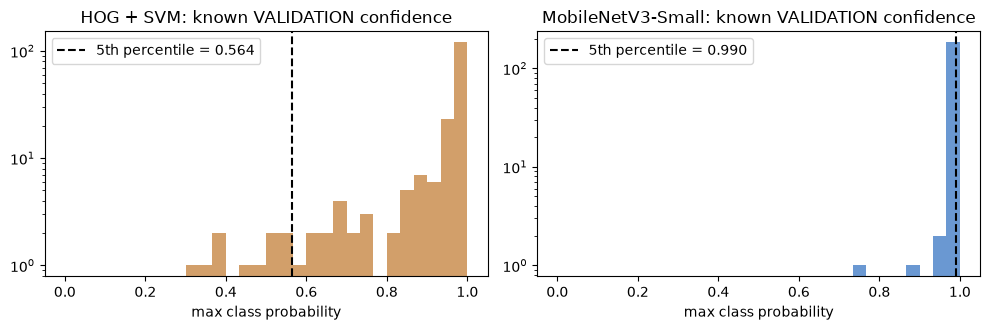

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, k in zip(axes, P):
    vc = max_confidence(P[k]["val_probs"]); thr = select_threshold(vc, cfg["threshold_percentile"])
    assert abs(thr - R[k]["threshold"]) < 1e-12   # recomputed from validation only == saved threshold
    ax.hist(vc, bins=30, range=(0, 1), color=COL[k], alpha=.7); ax.axvline(thr, color="k", ls="--", label=f"5th percentile = {thr:.3f}")
    ax.set_yscale("log"); ax.set_title(f"{NAMES[k]}: known VALIDATION confidence"); ax.set_xlabel("max class probability"); ax.legend()
plt.tight_layout(); plt.show()

By construction ~5% of known validation images fall below the threshold; this is a *design choice* (a 95% coverage target), not an optimum. No test or unknown image was used to choose it.

## 7. Unknown rejection by species

In [7]:
from scipy.stats import beta
def cp(k, n):
    return (0.0 if k == 0 else beta.ppf(.025, k, n - k + 1), 1.0 if k == n else beta.ppf(.975, k + 1, n - k))
rows = []
for k in P:
    thr = R[k]["threshold"]
    for s in ("Potato", "Bell pepper"):
        c = max_confidence(P[k]["unknown_probs"][(unk.species == s).values]); rej = int((c < thr).sum()); lo, hi = cp(rej, len(c))
        assert abs(rej / len(c) - R[k]["unknown_rejection_per_species"][s]) < 1e-12
        rows.append({"model": NAMES[k], "species": s, "n": len(c), "rejected": rej, "rate": round(rej / len(c), 3), "95% exact CI": f"{lo:.2f}-{hi:.2f}"})
display(pd.DataFrame(rows))

,model,species,n,rejected,rate,95% exact CI
0,HOG + SVM,Potato,150,16,0.107,0.06-0.17
1,HOG + SVM,Bell pepper,150,23,0.153,0.10-0.22
2,MobileNetV3-Small,Potato,150,91,0.607,0.52-0.69
3,MobileNetV3-Small,Bell pepper,150,128,0.853,0.79-0.91


## 8. Known-test uncertainty (exact binomial)

In [8]:
for k in P:
    n = len(y); c = int((P[k]["test_probs"].argmax(1) == y).sum()); print(NAMES[k], f"accuracy {c}/{n}, exact 95% CI = {cp(c, n)[0]:.3f}-{cp(c, n)[1]:.3f}")
print(json.load(open("artifacts/metrics/bootstrap_ci.json"))["mobilenet"])

HOG + SVM accuracy 186/188, exact 95% CI = 0.962-0.999
MobileNetV3-Small accuracy 188/188, exact 95% CI = 0.981-1.000
{'known_accuracy': [1.0, 1.0], 'known_coverage': [0.9148936170212766, 0.973404255319149], 'unknown_rejection': [0.68, 0.7833333333333333], 'auroc': [0.9277347074468085, 0.9661001773049646], 'clopper_pearson_exact': {'known_accuracy': [0.9805695533731766, 1.0], 'known_coverage': [0.9043563801731326, 0.9742011208981992], 'unknown_rejection': [0.6759812268278942, 0.7794117346713125]}}


The percentile bootstrap treats images as independent, holds the model, threshold and split fixed, and degenerates to [1, 1] for an all-correct sample. It captures test-sampling noise only.

## 9. AUROC and confidence distributions
AUROC (unknown = positive, anomaly score = −confidence) asks *how well does confidence rank unknowns below knowns across all thresholds?* The fixed threshold asks *what happens at one operating point?* They can disagree.

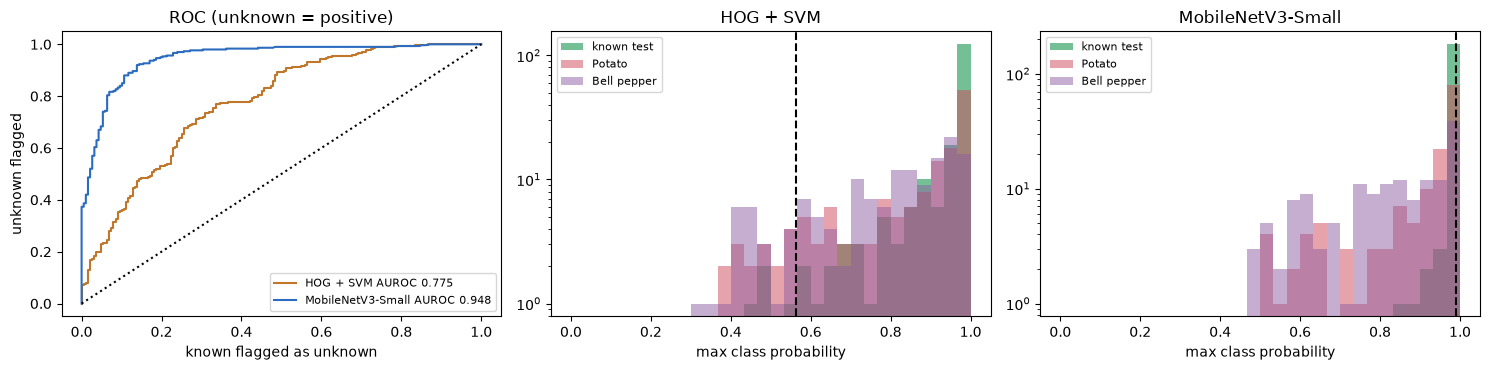

{'hog_svm': {'Potato': 0.7189716312056738, 'Bell pepper': 0.8301773049645389}, 'mobilenet': {'Potato': 0.918936170212766, 'Bell pepper': 0.9761347517730496}}


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for k in P:
    kc, uc = max_confidence(P[k]["test_probs"]), max_confidence(P[k]["unknown_probs"])
    a = auroc_unknown_vs_known(kc, uc); assert abs(a - R[k]["auroc_unknown_positive"]) < 1e-12
    mw = (uc[:, None] < kc[None, :]).mean() + .5 * (uc[:, None] == kc[None, :]).mean(); assert abs(a - mw) < 1e-9  # Mann-Whitney check
    yy = np.r_[np.zeros(len(kc)), np.ones(len(uc))]; f, t_, _ = roc_curve(yy, -np.r_[kc, uc]); axes[0].plot(f, t_, color=COL[k], label=f"{NAMES[k]} AUROC {a:.3f}")
axes[0].plot([0, 1], [0, 1], "k:"); axes[0].set_xlabel("known flagged as unknown"); axes[0].set_ylabel("unknown flagged"); axes[0].legend(fontsize=8); axes[0].set_title("ROC (unknown = positive)")
for ax, k in zip(axes[1:], P):
    ax.hist(max_confidence(P[k]["test_probs"]), bins=30, range=(0, 1), alpha=.65, label="known test", color="#2a9d5c")
    for s, c in (("Potato", "#d1495b"), ("Bell pepper", "#8e5ea2")):
        ax.hist(max_confidence(P[k]["unknown_probs"][(unk.species == s).values]), bins=30, range=(0, 1), alpha=.5, label=s, color=c)
    ax.axvline(R[k]["threshold"], color="k", ls="--"); ax.set_yscale("log"); ax.set_title(NAMES[k]); ax.legend(fontsize=8); ax.set_xlabel("max class probability")
plt.tight_layout(); plt.show()
print({k: R[k]["auroc_per_unknown_species"] for k in R})

## 10. Risk–coverage

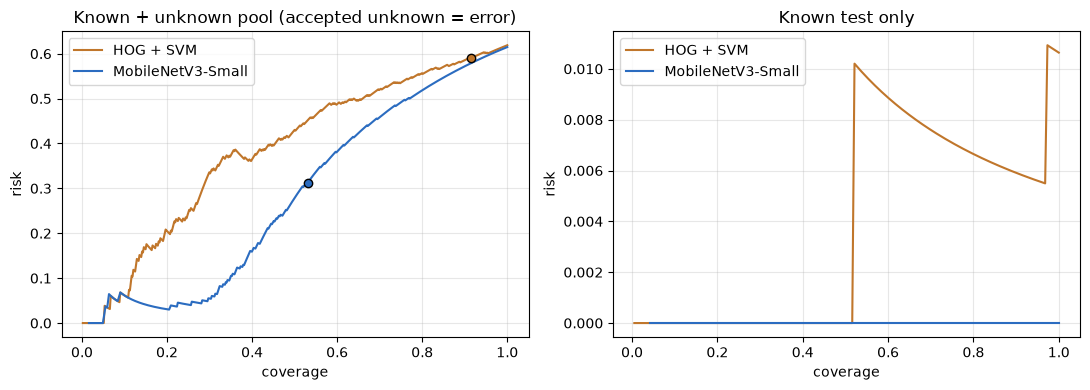

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k in P:
    conf, corr = combined_correctness(P[k]["test_probs"], y, P[k]["unknown_probs"]); _, cov, risk = risk_coverage(conf, corr)
    ax[0].plot(cov, risk, color=COL[k], label=NAMES[k]); r = combined_risk_at_threshold(P[k]["test_probs"], y, P[k]["unknown_probs"], R[k]["threshold"])
    assert abs(r["risk"] - R[k]["combined"]["risk"]) < 1e-12; ax[0].scatter(r["coverage"], r["risk"], color=COL[k], edgecolor="k", zorder=3)
    kc = max_confidence(P[k]["test_probs"]); _, c2, r2 = risk_coverage(kc, P[k]["test_probs"].argmax(1) == y); ax[1].plot(c2, r2, color=COL[k], label=NAMES[k])
ax[0].set_title("Known + unknown pool (accepted unknown = error)"); ax[1].set_title("Known test only")
for a in ax: a.set_xlabel("coverage"); a.set_ylabel("risk"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

**Pool risk depends on the mix.** 188 known vs 300 unknown images is an arbitrary ratio; the table shows the MobileNet pool risk if unknowns were a different share of the test pool (rates fixed at the saved operating point).

In [11]:
k = "mobilenet"; thr = R[k]["threshold"]; kc, uc = max_confidence(P[k]["test_probs"]), max_confidence(P[k]["unknown_probs"])
acc_k = kc >= thr; wrong_k = (P[k]["test_probs"].argmax(1) != y)[acc_k].sum() / len(kc); cov_k = acc_k.mean(); far = (uc >= thr).mean()
print(pd.DataFrame([{"unknown share": f"{s:.0%}", "pool risk": round(((1 - s) * wrong_k + s * far) / ((1 - s) * cov_k + s * far), 3)} for s in (.01, .1, .25, .5, .615, .9)]).to_string(index=False))

unknown share  pool risk
           1%      0.003
          10%      0.031
          25%      0.087
          50%      0.222
          62%      0.313
          90%      0.720


## 11. Failure cases

MobileNet: accepted unknown leaves, by true species and predicted known class


col_0,Apple,Peach,Tomato
row_0,,,
Bell pepper,6,4,12
Potato,7,0,52


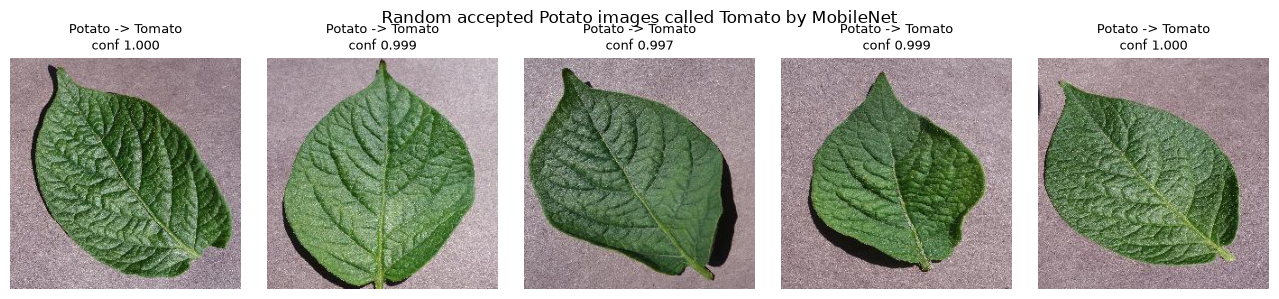

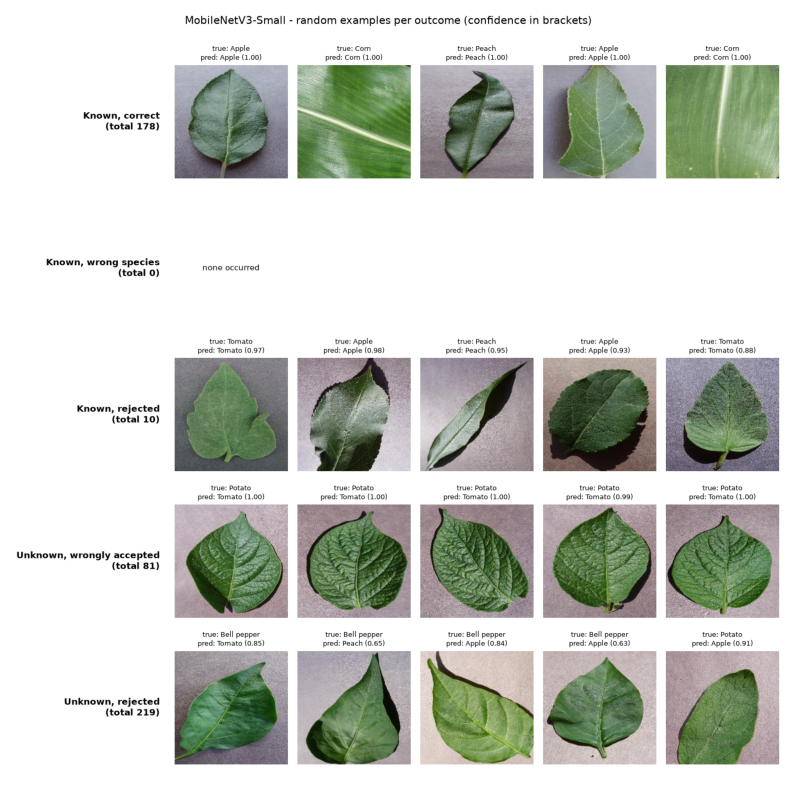

In [12]:
unk_pred = np.array(classes)[P["mobilenet"]["unknown_probs"].argmax(1)]; acc_m = max_confidence(P["mobilenet"]["unknown_probs"]) >= R["mobilenet"]["threshold"]
print("MobileNet: accepted unknown leaves, by true species and predicted known class")
display(pd.crosstab(unk.species.values[acc_m], unk_pred[acc_m]))
sel = unk[(acc_m) & (unk_pred == "Tomato") & (unk.species == "Potato").values].sample(5, random_state=42)
fig, axes = plt.subplots(1, 5, figsize=(13, 3))
for ax, (i, r) in zip(axes, sel.iterrows()):
    pos = unk.index.get_loc(i); ax.imshow(Image.open(r.path).convert("RGB")); ax.axis("off")
    ax.set_title(f"Potato -> Tomato\nconf {P['mobilenet']['unknown_probs'][pos].max():.3f}", fontsize=9)
plt.suptitle("Random accepted Potato images called Tomato by MobileNet"); plt.tight_layout(); plt.show()
plt.figure(figsize=(10, 12)); plt.imshow(Image.open("artifacts/figures/failure_gallery_mobilenet.png")); plt.axis("off"); plt.show()

A softmax confidence only measures how far an input is from the decision boundaries *among known classes*. A Potato leaf that looks more like Tomato than like Apple/Corn/Grape/Peach can sit far from every boundary and receive high confidence. Softmax is also uncalibrated.

## 12. Possible specimen overlap: audit and sensitivity split

{'images_with_explicit_leaf_number': 100, 'distinct_leaf_numbers': 96, 'leaf_numbers_spanning_multiple_splits_in_primary': 1, 'images_whose_leaf_number_appears_in_another_split': 2}


,species,split,n,within_1,within_5,median_gap
0,Apple,val,37,8,27,3.0
1,Apple,test,38,5,26,3.0
2,Corn,val,38,20,38,1.0
3,Corn,test,37,20,37,1.0
4,Grape,val,37,28,37,1.0
5,Grape,test,38,20,38,1.0
6,Peach,val,37,28,37,1.0
7,Peach,test,38,27,38,1.0
8,Tomato,val,23,4,17,4.0
9,Tomato,test,25,4,16,3.0


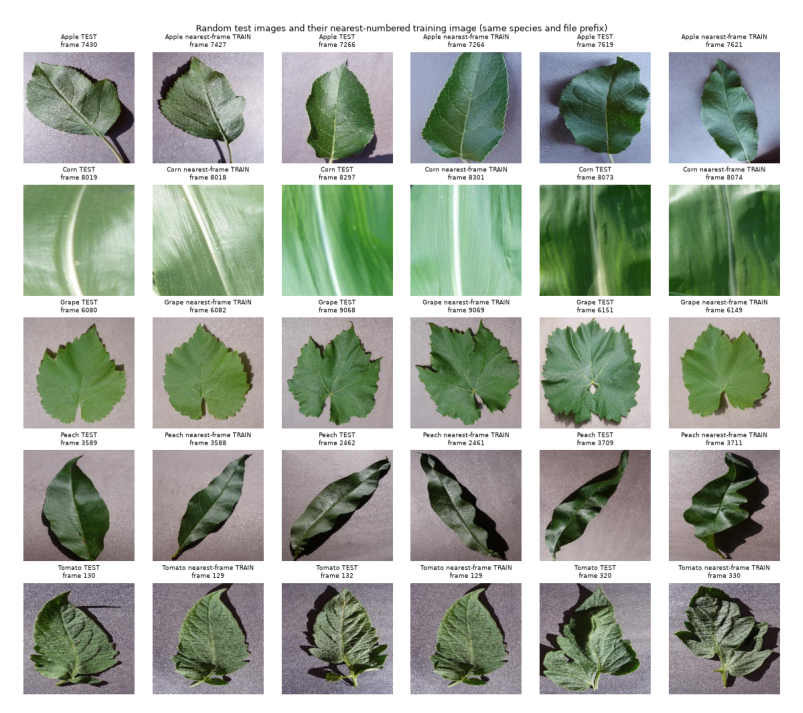

| Model | Split | Known test n | Known acc | Threshold | Unknown rejected | Potato rejected | Bell pepper rejected | AUROC | AUROC 95% CI |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| HOG + SVM | primary (image-level) | 188 | 0.989 | 0.564 | 0.13 | 0.107 | 0.153 | 0.775 | 0.730-0.818 |
| HOG + SVM | frame-block + guard | 188 | 0.957 | 0.614 | 0.193 | 0.147 | 0.24 | 0.748 | 0.702-0.793 |
| MobileNetV3-Small | primary (image-level) | 188 | 1.0 | 0.99 | 0.73 | 0.607 | 0.853 | 0.948 | 0.928-0.966 |
| MobileNetV3-Small | frame-block + guard | 188 | 1.0 | 0.997 | 0.66 | 0.407 | 0.913 | 0.919 | 0.894-0.942 |



In [13]:
a = json.load(open("artifacts/metrics/leakage_audit.json"))
print({k: v for k, v in a.items() if k.startswith(("images", "distinct", "leaf"))})
display(pd.DataFrame(a["frame_proximity_primary"]))
plt.figure(figsize=(12, 9)); plt.imshow(Image.open("artifacts/figures/frame_neighbours.png")); plt.axis("off"); plt.show()
print(open("artifacts/metrics/split_sensitivity.md").read())

- Leaf numbers exist for only 100 Tomato files, so a specimen-level split is **not possible**. Frame adjacency is **not** proof of the same leaf (many neighbours above are clearly different leaves, some may be the same).
- The frame-block split keeps nearby frames together and drops images within 5 frames of another split. It is a robustness check, not specimen independence.
- Under it MobileNet keeps 100% accuracy but unknown rejection falls 0.730 → 0.660 and AUROC 0.948 → 0.919 (CIs overlap). Test images and thresholds also differ and only one seed was run, so this is *consistent with mild optimism* in the primary numbers but not proof.

## 13. Synthetic perturbation test

In [14]:
s = json.load(open("artifacts/metrics/stress_test.json"))
for k in s:
    for kind, rows in s[k].items(): print(NAMES[k], kind, [(r["level"], round(r["accuracy"], 3), round(r["coverage"], 3)) for r in rows])

HOG + SVM brightness [(0.4, 0.979, 0.989), (0.7, 0.984, 0.984), (1.0, 0.989, 0.984), (1.3, 0.979, 0.968), (1.6, 0.926, 0.952)]
HOG + SVM blur_radius [(0, 0.989, 0.984), (1, 0.947, 0.957), (2, 0.686, 0.777), (4, 0.207, 0.846)]
MobileNetV3-Small brightness [(0.4, 0.995, 0.92), (0.7, 1.0, 0.941), (1.0, 1.0, 0.947), (1.3, 1.0, 0.936), (1.6, 1.0, 0.926)]
MobileNetV3-Small blur_radius [(0, 1.0, 0.947), (1, 1.0, 0.936), (2, 0.984, 0.803), (4, 0.926, 0.505)]


Brightness/blur applied to known test images measure sensitivity to two synthetic changes only; they are **not** evidence about field photography.

## 14. Conclusions and limitations
**Supported by the data:** H1 (both ≥ 0.95 accuracy), H2 (AUROC 0.948 vs 0.775; unknown rejection 0.73 vs 0.13), H3 (27% of unknowns accepted, Potato mostly as Tomato), H4 (risk falls as coverage falls).

**Not established:** generalisation to field images (PlantVillage is lab-style, uniform background); behaviour for other species (only two withheld); calibration; independence of train/test specimens; seed-to-seed variation (single seed).

Closed-set accuracy therefore says little about knowing what is unknown, and a fixed confidence threshold is a safeguard, not botanical identification.